# AER_AI Plume Boundary Inspection

Purpose: (1) inspect the AER_AI value distribution to sanity-check the
plume/background separation, and (2) define a per-day inclusion boundary
that removes non-plume "noise" regions (sparse near-source pixel gaps,
isolated aerosol patches unrelated to the fire) before the AI-threshold
mask is applied.

This replaces the ad hoc, notebook-local clips used previously
(`plume[160:, :] = False` in nb02, `np.where(lon > -72, clip(ai, 0, 1.99), ai)`
in nb03) with one explicit, saved boundary per date. Output is
`data/{MMDD}/plume_boundary.geojson`, loadable via `plume_helpers.load_plume_boundary`.

**How to use this notebook:** run Sections 1-2 to load data and set the AI
threshold. Section 3 clusters all AI>threshold pixels into spatial blobs
(DBSCAN) and plots them numbered by size — the real plume is usually one or
more of the larger blobs; small isolated blobs are noise. Edit
`KEEP_BLOB_IDS` in Section 4 to the ids you want to keep, then run Section 4
to build, validate, and save the boundary. No interactive clicking or
special matplotlib backend required — this runs the same live or headless.


## Section 1 — Load AER_AI (all overpasses, concatenated)

In [1]:
get_ipython().run_line_magic('cd', '..')
from pathlib import Path
import glob
from collections import defaultdict

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from src.data_helpers import load_aer_ai, get_modis_hotspot
from src import plume_helpers as ph

ROOT = Path(".").resolve()
matplotlib.rcParams.update({"font.size": 10, "figure.dpi": 120})
print("ROOT:", ROOT)


/Users/maperezc/Downloads/wildfires
ROOT: /Users/maperezc/Downloads/wildfires


In [34]:
# ── Case study parameters ──────────────────────────────────────────────────
DATA_DIR = ROOT / "data"

FIRE_DATE: str = "2026-01-17"
TARGET_DAY: str = "".join(FIRE_DATE.split("-")[1:])   # "0118"

AER_AI_L2_PATTERN = DATA_DIR / TARGET_DAY / "S5P_OFFL_L2__AER_AI_2026*"
AER_AI_L2_PATH = sorted(glob.glob(str(AER_AI_L2_PATTERN)))
assert AER_AI_L2_PATH, f"No AER_AI files found for pattern: {AER_AI_L2_PATTERN}"

HOTSPOT_CSV: Path = DATA_DIR / "daily_dominant_hotspot_summary.csv"

QA_THRESH: float = 0.5
QA_UINT8: int = int(QA_THRESH * 100)

# Domain-of-interest bounds, consistent with data_helpers defaults used
# elsewhere in the pipeline (nb02/nb03).
LAT_MIN, LAT_MAX = -47.0, -26.0
LON_MIN, LON_MAX = -82.0, -62.0

OUT_PATH = DATA_DIR / TARGET_DAY / "plume_boundary.geojson"

print(f"{len(AER_AI_L2_PATH)} AER_AI overpass file(s) for {FIRE_DATE}:")
for p in AER_AI_L2_PATH:
    print(" ", Path(p).name)


1 AER_AI overpass file(s) for 2026-01-17:
  S5P_OFFL_L2__AER_AI_20260117T175420_20260117T193550_42823_03_020901_20260119T075617.nc


In [35]:
def load_and_concat(paths, loader, **kwargs):
    """Concatenate a loader's output across multiple L2 overpass files."""
    chunks = defaultdict(list)
    scalars = {}
    for pth in paths:
        pth = Path(pth)
        data = loader(pth, **kwargs)
        if data is None:
            continue  # skip orbits with no valid pixels in the ROI
        for k, v in data.items():
            if isinstance(v, np.ndarray):
                chunks[k].append(v)
            else:
                scalars[k] = v
    out = {k: np.concatenate(v) for k, v in chunks.items()}
    out.update(scalars)
    return out


roi_kwargs = dict(
    lat_min=LAT_MIN,
    lat_max=LAT_MAX,
    lon_min=LON_MIN,
    lon_max=LON_MAX,
    qa_threshold=QA_UINT8,
)

ai_data = load_and_concat(AER_AI_L2_PATH, load_aer_ai, **roi_kwargs)
ai, lat, lon = ai_data["ai"], ai_data["lat"], ai_data["lon"]
assert ai.size > 0, "No AER_AI pixels loaded across all overpasses."
print(f"Concatenated AER_AI pixels: {ai.size} (from {len(AER_AI_L2_PATH)} overpasses)")

# ── Fire centroid (MODIS), for reference on the blob plot ─────────────────
modis = get_modis_hotspot(HOTSPOT_CSV, FIRE_DATE,
                           lat_min=LAT_MIN, lat_max=LAT_MAX,
                           lon_min=LON_MIN, lon_max=LON_MAX)
assert len(modis) > 0, f"No MODIS dominant-hotspot row found for {FIRE_DATE}."
FIRE_LAT, FIRE_LON = modis["dominant_lat"].values[0], modis["dominant_lon"].values[0]
print(f"Fire centroid: ({FIRE_LAT:.4f}, {FIRE_LON:.4f})")


Concatenated AER_AI pixels: 145323 (from 1 overpasses)
Fire centroid: (-36.7818, -72.9073)


## Section 2 — AI distribution and background-based threshold

`plume_helpers.robust_ai_threshold` computes `median + k * MAD` over the
**entire** domain sample. Plume pixels are a small minority of the loaded
domain, so this is dominated by background AI and needs no hand-picked
clean region. Sweep a few `k` values below, then pick one by eye against
the histogram and the current pipeline constant (`AI_THRESHOLD = 2.0`).

k= 2.0  threshold=0.889  (median=-0.050, mad=0.470)
k= 3.0  threshold=1.359  (median=-0.050, mad=0.470)
k= 4.0  threshold=1.828  (median=-0.050, mad=0.470)
k= 5.0  threshold=2.298  (median=-0.050, mad=0.470)


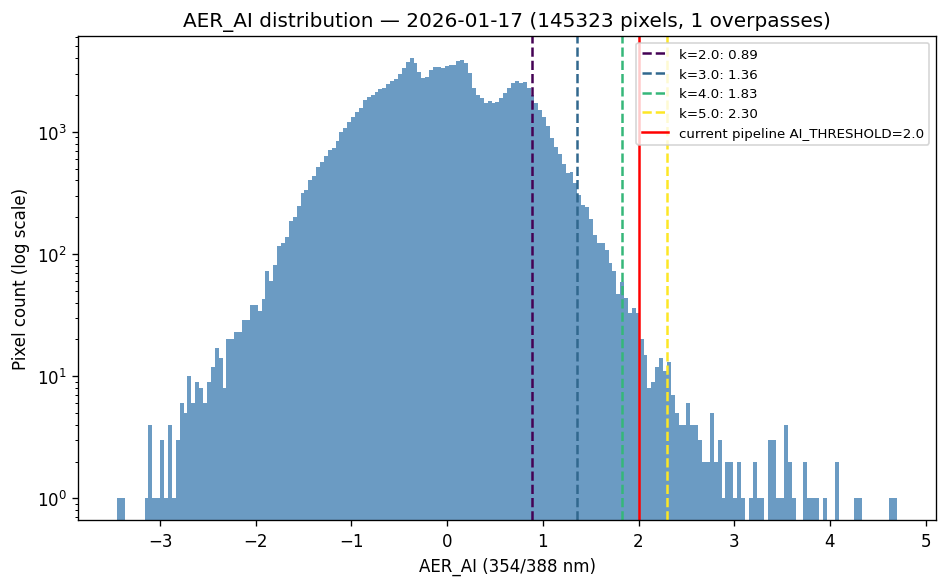

In [36]:
K_CANDIDATES = [2.0, 3.0, 4.0, 5.0]
CURRENT_PIPELINE_AI_THRESHOLD = 2.0  # nb02 / nb03 constant, for reference only

candidate_results = {k: ph.robust_ai_threshold(ai, k) for k in K_CANDIDATES}
for k, res in candidate_results.items():
    print(f"k={k:>4.1f}  threshold={res.threshold:.3f}  "
          f"(median={res.median:.3f}, mad={res.mad:.3f})")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(ai, bins=200, color="steelblue", alpha=0.8, log=True)
colors = plt.cm.viridis(np.linspace(0, 1, len(K_CANDIDATES)))
for (k, res), c in zip(candidate_results.items(), colors):
    ax.axvline(res.threshold, color=c, ls="--", lw=1.5, label=f"k={k}: {res.threshold:.2f}")
ax.axvline(CURRENT_PIPELINE_AI_THRESHOLD, color="red", ls="-", lw=1.5,
           label=f"current pipeline AI_THRESHOLD={CURRENT_PIPELINE_AI_THRESHOLD}")
ax.set_xlabel("AER_AI (354/388 nm)")
ax.set_ylabel("Pixel count (log scale)")
ax.set_title(f"AER_AI distribution — {FIRE_DATE} ({ai.size} pixels, {len(AER_AI_L2_PATH)} overpasses)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


In [37]:
# ── Threshold used for drawing/masking — starts at the current pipeline
# constant (2.0); override AI_THRESHOLD directly once you've inspected the
# histogram above. `k_equiv` reports how many MAD above the domain median
# this choice sits, for comparison with the k-sweep.
AI_THRESHOLD: float = 2.0

_diag = ph.robust_ai_threshold(ai, k=1.0)  # k=1.0 just to recover median/mad; unused as a threshold
k_equiv = (AI_THRESHOLD - _diag.median) / _diag.mad
threshold_result = ph.ThresholdResult(
    threshold=AI_THRESHOLD, median=_diag.median, mad=_diag.mad, k=k_equiv
)
print(threshold_result)
print(f"AI_THRESHOLD = {AI_THRESHOLD} is {k_equiv:.2f} MAD above the domain median.")


ThresholdResult(threshold=2.0, median=-0.0501086451113224, mad=0.4695377051830292, k=4.366227935437422)
AI_THRESHOLD = 2.0 is 4.37 MAD above the domain median.


## Section 3 — Cluster AI>threshold pixels into blobs

`plume_helpers.cluster_ai_blobs` groups all AI>threshold pixels by spatial
proximity (DBSCAN, haversine distance) into blobs, ranked by descending
pixel count. `eps_km` is the neighborhood radius connecting two pixels
(a few TROPOMI pixel widths); `min_samples` is the minimum blob size —
smaller/sparser groups are dropped as DBSCAN noise (label -1) automatically,
before you even choose which blobs to keep.


10 blob(s) found (69 noise pixels dropped by DBSCAN):
  blob_id= 0  size=   57  centroid=(-35.62, -70.60)
  blob_id= 1  size=   18  centroid=(-26.26, -69.09)
  blob_id= 2  size=   13  centroid=(-36.11, -70.35)
  blob_id= 3  size=   11  centroid=(-29.90, -70.36)
  blob_id= 4  size=    9  centroid=(-41.11, -69.40)
  blob_id= 5  size=    8  centroid=(-27.89, -69.31)
  blob_id= 6  size=    7  centroid=(-29.37, -69.95)
  blob_id= 7  size=    6  centroid=(-34.62, -70.35)
  blob_id= 8  size=    6  centroid=(-29.97, -69.92)
  blob_id= 9  size=    5  centroid=(-33.09, -70.96)


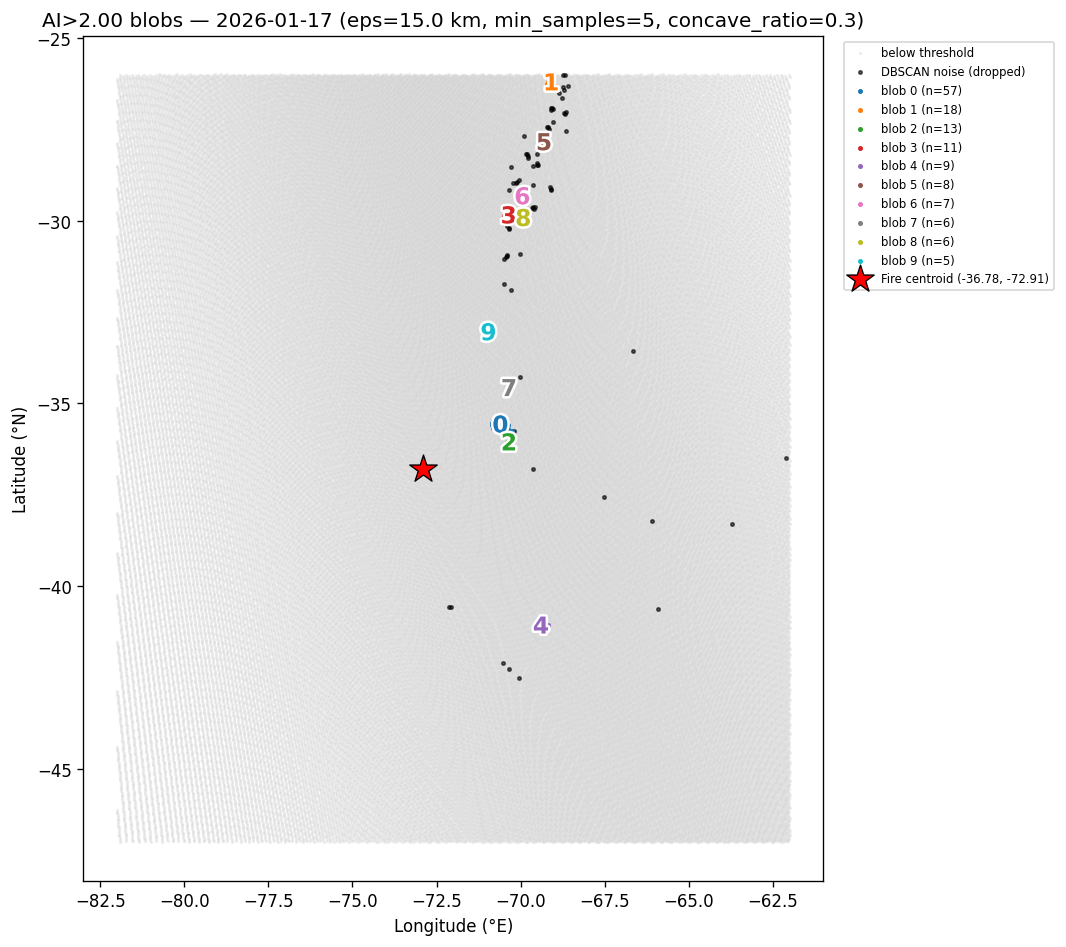

In [38]:
# DBSCAN + hull parameters — tune by eye against the plot below.
EPS_KM: float = 15.0          # ~2-4 TROPOMI pixel widths (nadir pixel ~3.5x7 km)
MIN_SAMPLES: int = 5          # minimum pixels for a group to count as a blob
CONCAVE_RATIO: float = 0.3    # 0 = hug pixel footprint tightly, 1 = convex hull

clustering = ph.cluster_ai_blobs(
    lat, lon, ai, threshold_result.threshold,
    eps_km=EPS_KM, min_samples=MIN_SAMPLES, concave_ratio=CONCAVE_RATIO,
)

print(f"{len(clustering.blobs)} blob(s) found "
      f"({int((clustering.labels == -1).sum())} noise pixels dropped by DBSCAN):")
for b in clustering.blobs:
    print(f"  blob_id={b.blob_id:>2d}  size={b.size:>5d}  "
          f"centroid=({b.centroid_lat:.2f}, {b.centroid_lon:.2f})")

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(lon[clustering.labels == -2], lat[clustering.labels == -2],
           c="lightgray", s=1, alpha=0.3, rasterized=True, label="below threshold")
ax.scatter(lon[clustering.labels == -1], lat[clustering.labels == -1],
           c="black", s=4, alpha=0.6, rasterized=True, label="DBSCAN noise (dropped)")

cmap = plt.cm.tab10
for b in clustering.blobs:
    in_blob = clustering.labels == b.blob_id
    color = cmap(b.blob_id % 10)
    ax.scatter(lon[in_blob], lat[in_blob], s=4, color=color, label=f"blob {b.blob_id} (n={b.size})")
    ax.annotate(str(b.blob_id), (b.centroid_lon, b.centroid_lat),
                fontsize=14, fontweight="bold", color=color, ha="center", va="center",
                path_effects=[pe.withStroke(linewidth=3, foreground="white")])

ax.scatter(FIRE_LON, FIRE_LAT, marker="*", s=300, c="red", edgecolors="black",
           linewidths=0.8, zorder=10, label=f"Fire centroid ({FIRE_LAT:.2f}, {FIRE_LON:.2f})")

ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.set_title(f"AI>{threshold_result.threshold:.2f} blobs — {FIRE_DATE} "
             f"(eps={EPS_KM} km, min_samples={MIN_SAMPLES}, concave_ratio={CONCAVE_RATIO})")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.02, 1.0))
fig.tight_layout()
plt.show()

## Section 4 — Finalize, validate, and save

Set `KEEP_BLOB_IDS` to the `blob_id`s from the plot above that are the real
plume (typically blob 0, the largest — but check the centroid/size printout,
a real fire plume can fragment into more than one blob). Everything else
(other blobs + DBSCAN noise) is dropped as noise.


In [27]:
# Blob id(s) to keep as the plume — inspect the numbered plot above and edit.
KEEP_BLOB_IDS: list[int] = [3,0,2]

boundary = ph.build_boundary_from_blobs(clustering, KEEP_BLOB_IDS)
print(boundary.geom_type, "- area:", boundary.area)


MultiPolygon - area: 2.1061558021319797


Plume pixels: 391 / 108373 (0.36%)


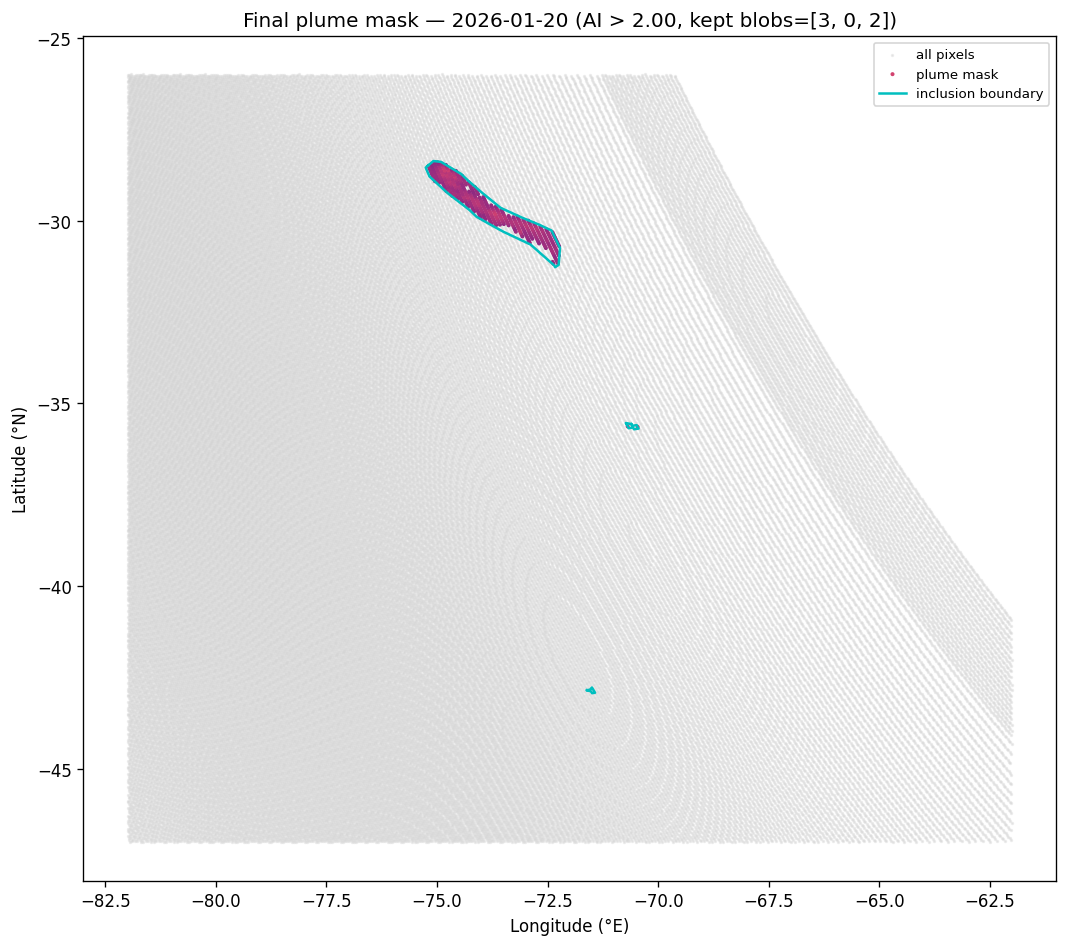

In [28]:
mask = ph.plume_mask(lat, lon, ai, boundary, threshold_result.threshold)
print(f"Plume pixels: {int(mask.sum())} / {ai.size} "
      f"({100 * mask.sum() / ai.size:.2f}%)")

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(lon, lat, c="lightgray", s=1, alpha=0.4, rasterized=True, label="all pixels")
ax.scatter(lon[mask], lat[mask], c=ai[mask], cmap="magma", vmin=0, vmax=5, s=2, rasterized=True,
           label="plume mask")

# boundary may be a Polygon or a MultiPolygon (union of >1 kept blob hulls)
polygons = boundary.geoms if boundary.geom_type == "MultiPolygon" else [boundary]
for i, poly in enumerate(polygons):
    px, py = poly.exterior.xy
    ax.plot(px, py, "c-", lw=1.5, label="inclusion boundary" if i == 0 else None)

ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.set_title(f"Final plume mask — {FIRE_DATE} (AI > {threshold_result.threshold:.2f}, "
             f"kept blobs={KEEP_BLOB_IDS})")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


In [9]:
ph.save_plume_boundary(
    path=OUT_PATH,
    date=FIRE_DATE,
    boundary=boundary,
    threshold_result=threshold_result,
    source_files=[Path(p).name for p in AER_AI_L2_PATH],
)
print(f"Saved plume boundary to {OUT_PATH}")

reloaded = ph.load_plume_boundary(OUT_PATH)
print(reloaded)


Saved plume boundary to /Users/maperezc/Downloads/wildfires/data/0119/plume_boundary.geojson
PlumeBoundary(boundary=<MULTIPOLYGON (((-72.916 -35.879, -72.786 -35.82, -72.642 -35.839, -72.779 -...>, threshold=2.0, date='2026-01-19', median=0.017152346670627594, mad=0.4298573434352875, k=4.6128039537095376, source_files=('S5P_OFFL_L2__AER_AI_20260119T171626_20260119T185756_42851_03_020901_20260121T071734.nc', 'S5P_OFFL_L2__AER_AI_20260119T185756_20260119T203926_42852_03_020901_20260121T085807.nc'), git_hash='3daa181', created_at='2026-07-02T07:46:39.299933+00:00')
